# Test of Monte Carlo simulation

- For testing, we use a 1-year planning horizon to test the process (comparing output distributions against fitted ones).
- An arbitrary constant attenuation probability $\alpha = 0.5$ was fixed for this testing phase.
- This notebook includes tests on severity levels (instead of continuous) that were not further kept.

In [11]:
%reload_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
import ast
import json
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from scipy.optimize import minimize
from rosenheim_TTR import damage_to_severity, evaluate_proxies_continuous_Klibi

from monte_carlo import generate_mc_scenario_only, is_warehouse_hit

In [ ]:
SEED = 22
np.random.seed(SEED)

NB_N_MONTHLY = 1.40
NB_P_MONTHLY = 0.264

ALPHA = 0.25 # arbitrary constant alpha
DAYS_PER_YEAR = 365
N_YEARS = 1 # planning horizon
N_SCENARIOS = 100

df_raw_events = pd.read_csv("../Data/Results/CLEAN_disasters_europe.csv")

In [3]:
# because sometimes the country names recorded are in tuples
def clean_country_name(country) :

    if not isinstance(country, str) :
        return str(country)
    s = country.strip().strip("'\"")
    
    if country.startswith("(") and country.endswith(")") :
        try :
            parsed = ast.literal_eval(country)
            if isinstance(parsed, tuple) and len(parsed) > 0:
                return str(parsed[0]).strip()
        except Exception:
            pass

    for c in [",", ")", "(", "'", '"'] :
        s = s.replace(c, "")
    return s.strip()

df_raw_events["country_clean"] = df_raw_events["Country"].apply(clean_country_name)

In [4]:
N_EUROPE_EVENTS = len(df_raw_events)

COUNTRY_WEIGHTS = (df_raw_events.groupby("Country")["DisNo."].count() / N_EUROPE_EVENTS).to_dict()

DURATIONS = df_raw_events.groupby("country_clean")["event_duration"].apply(list).to_dict()
DURATIONS["Fallback"] = df_raw_events["event_duration"].dropna().tolist()

# ==============================================================================

print("Extracted Country Weights (Top 5):")
for c in list(COUNTRY_WEIGHTS.keys())[:5]:
    print(f"  {c}: {COUNTRY_WEIGHTS[c]:.4f}")

Extracted Country Weights (Top 5):
  Albania: 0.0195
  Austria: 0.0277
  Belarus: 0.0053
  Belgium: 0.0313
  Bosnia and Herzegovina: 0.0171


In [5]:
df_alpha = pd.read_csv("../Data/Results/attenuation_probas.csv")
alpha_lookup = dict(zip(df_alpha["Country"], df_alpha["alpha"]))

In [6]:
wh_country_map = {
    "Dusseldorf": "Germany",
    "Toulouse": "France",
    "Turin": "Italy"
}

with open("../Data/Dummy_examples/dummySN_chap7.json", "r") as f:
    network_config = json.load(f)

CANDIDATE_WAREHOUSES = {
    wh: {
        "country" : wh_country_map[wh],
        "b_w" : network_config["capacities"][wh],
        "alpha" : alpha_lookup[wh_country_map[wh]]
    } for wh in network_config["warehouses"]
}
CANDIDATE_WAREHOUSES

{'Dusseldorf': {'country': 'Germany',
  'b_w': 50000,
  'alpha': 0.1950203114176292},
 'Toulouse': {'country': 'France', 'b_w': 50000, 'alpha': 0.1784314270696093},
 'Turin': {'country': 'Italy', 'b_w': 50000, 'alpha': 0.2017065804625539}}

In [9]:
df_event_scenarios = generate_mc_scenario_only(
    nb_n_monthly = NB_N_MONTHLY,
    n_years = N_YEARS,
    nb_p = NB_P_MONTHLY,
    country_weights = COUNTRY_WEIGHTS,
    duration_pools = DURATIONS,
    num_scenarios = N_SCENARIOS,
    severity_function = "severity_proxy",
    seed = SEED
)

df_event_scenarios["severity_level"] = df_event_scenarios["severity"].apply(damage_to_severity)

df_facility_hits = is_warehouse_hit(CANDIDATE_WAREHOUSES, df_event_scenarios, default_alpha = ALPHA)
df_facility_hits["severity_level"] = df_facility_hits["severity"].apply(damage_to_severity)

In [13]:
if not df_facility_hits.empty:
    df_facility_hits["days_closed"] = df_facility_hits.apply(
        lambda r: evaluate_proxies_continuous_Klibi(r["duration_days"], r["severity"])["days_closed_ttr"] if r["is_hit"] else 0.0,
        axis=1
    )
else:
    df_facility_hits["days_closed"] = 0.0

print(f"Total Planning Horizon:          {N_YEARS} Years")
print(f"Total European Events Generated: {len(df_event_scenarios)}")
print(f"Facility Exposures Evaluated:    {len(df_facility_hits)}")
print(f"Direct Facility Strikes:         {df_facility_hits['is_hit'].sum()}")

Total Planning Horizon:          1 Years
Total European Events Generated: 5320
Facility Exposures Evaluated:    1257
Direct Facility Strikes:         223


In [17]:
df_facility_hits.head()

,scenario_id,year,month,event_id,country,warehouse,is_hit,duration_days,severity,severity_level,days_closed
0,s_1,1,1,evt_1,France,Toulouse,False,5,5.510394e+03,1,0.0
1,s_1,1,2,evt_6,France,Toulouse,False,2,2.210774e+05,3,0.0
2,s_1,1,2,evt_7,Germany,Dusseldorf,False,25,1.461507e+03,1,0.0
3,s_1,1,3,evt_15,Germany,Dusseldorf,False,10,6.185351e+06,4,0.0
4,s_1,1,4,evt_16,France,Toulouse,False,5,1.279059e+07,4,0.0


## Validation of MC simulation

**Source:** The three following cells to investigate generated distributions were written by Gemini.

Retained 5320 of 5320 simulated events (100.00%) with positive damage for distribution validation.


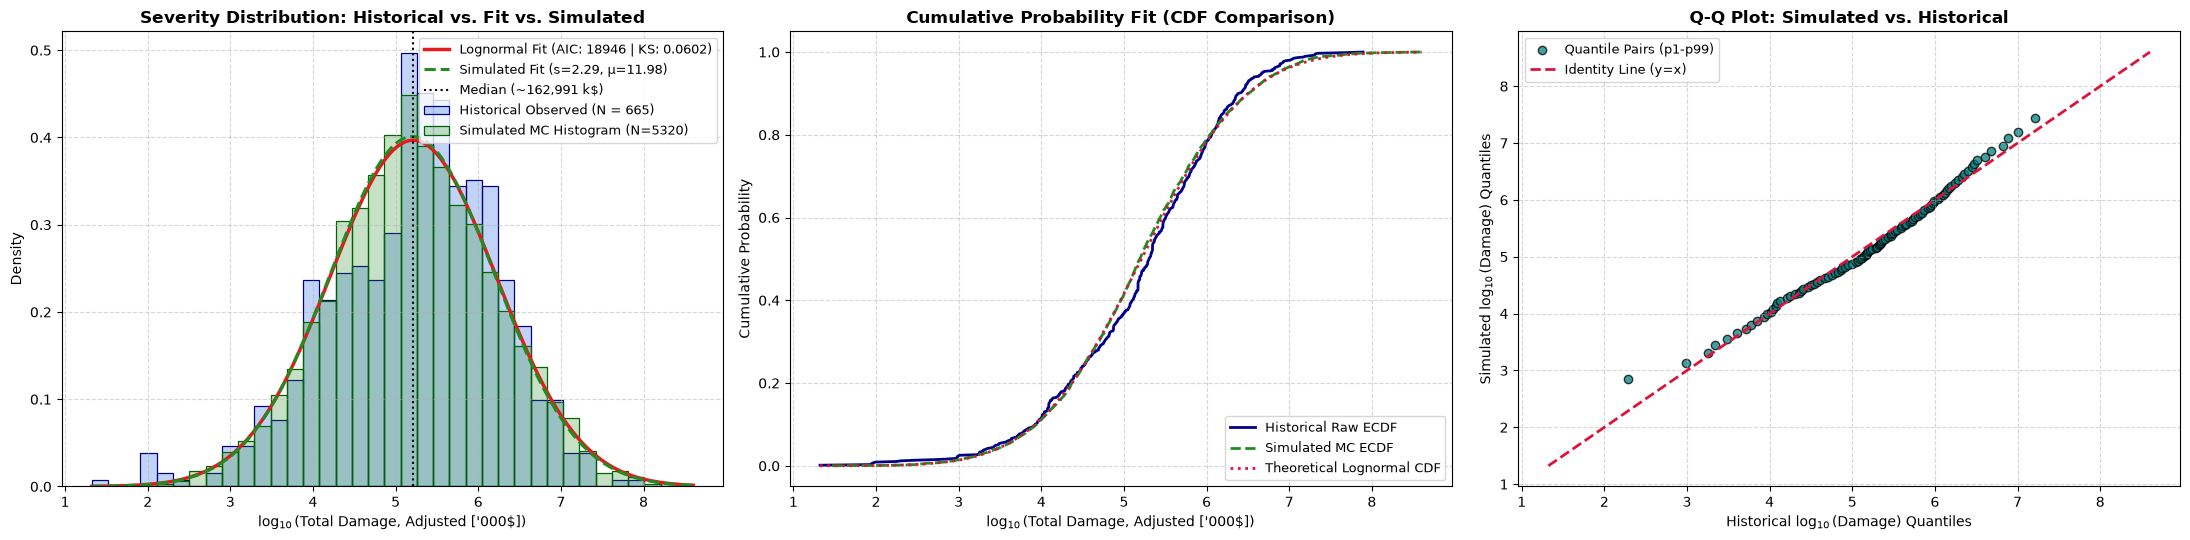

TWO-SAMPLE KS TEST (Simulated Events vs. Historical Raw):
  KS Statistic: 0.0686
  p-value:      0.0074 (Statistically distinct)


In [19]:
raw_damage = df_raw_events["Total Damage, Adjusted ('000 US$)"].dropna()
x_raw = raw_damage[raw_damage > 0].to_numpy()
log10_raw_damage = np.log10(x_raw)

sim_damage = df_event_scenarios["severity"].dropna().to_numpy()
x_sim = sim_damage[sim_damage > 0]
print(f"Retained {len(x_sim)} of {len(sim_damage)} simulated events ({(len(x_sim)/len(sim_damage))*100:.2f}%) with positive damage for distribution validation.")
log10_sim = np.log10(x_sim)

# parameters from damage fit
s=2.314686
loc=0.0
mu=12.001452
lognorm_dist = stats.lognorm(s = s, loc = loc, scale = np.exp(mu))

min_val = min(log10_raw_damage.min(), log10_sim.min())
max_val = max(log10_raw_damage.max(), log10_sim.max())
y_grid = np.linspace(min_val, max_val, 400)
x_grid = 10 ** y_grid

pdf_log10_theory = lognorm_dist.pdf(x_grid) * x_grid * np.log(10)
cdf_theory = lognorm_dist.cdf(x_grid)

s_sim, loc_sim, scale_sim = stats.lognorm.fit(x_sim, floc = 0)
lognorm_sim = stats.lognorm(s = s_sim, loc = loc_sim, scale = scale_sim)
pdf_log10_sim = lognorm_sim.pdf(x_grid) * x_grid * np.log(10)

params = (s, loc, np.exp(mu))
k = 2
log_lik = np.sum(stats.lognorm.logpdf(x_raw, *params))
aic = 2 * k - 2 * log_lik
bic = k * np.log(len(x_raw)) - 2 * log_lik
ks_stat, p_val = stats.kstest(x_raw, 'lognorm', args=params)

fig, axes = plt.subplots(1, 3, figsize = (22,5.5))
bins = np.linspace(min_val, max_val, 38)

sns.histplot(log10_raw_damage, bins = bins, stat = "density", ax = axes[0], color = "cornflowerblue", edgecolor = "navy", alpha = 0.40, 
                label = f"Historical Observed (N = {len(x_raw)})")
sns.histplot(
    log10_sim,
    bins=bins,
    stat="density",
    ax=axes[0],
    color="forestgreen",
    edgecolor="darkgreen",
    alpha=0.25,
    label=f"Simulated MC Histogram (N={len(x_sim)})"
)
axes[0].plot(
    y_grid,
    pdf_log10_theory,
    color='#e41a1c',
    linewidth=2.5,
    label=f'Lognormal Fit (AIC: {aic:.0f} | KS: {ks_stat:.4f})',
)
axes[0].plot(
    y_grid,
    pdf_log10_sim,
    color="forestgreen",
    linewidth=2.2,
    linestyle="--",
    label=f"Simulated Fit (s={s_sim:.2f}, μ={np.log(scale_sim):.2f})",
)
axes[0].axvline(
    np.log10(np.exp(mu)),
    color="black",
    linestyle=":",
    linewidth=1.5,
    label=f"Median (~{np.exp(mu):,.0f} k$)"
)

axes[0].set_title("Severity Distribution: Historical vs. Fit vs. Simulated", weight="bold")
axes[0].set_xlabel(r"$\log_{10}(\text{Total Damage, Adjusted ['000\$]})$")
axes[0].set_ylabel("Density")
axes[0].legend(fontsize=9, loc="upper right")
axes[0].grid(True, linestyle="--", alpha=0.5)

sorted_raw_damage = np.sort(log10_raw_damage)
ecdf_raw_damage = np.arange(1, len(sorted_raw_damage) + 1) / len(sorted_raw_damage)
sorted_sim = np.sort(log10_sim)
ecdf_sim = np.arange(1, len(sorted_sim) + 1) / len(sorted_sim)

axes[1].plot(sorted_raw_damage, ecdf_raw_damage, color="darkblue", linewidth=2.0, label="Historical Raw ECDF")
axes[1].plot(sorted_sim, ecdf_sim, color="forestgreen", linewidth=2.0, linestyle="--", label="Simulated MC ECDF")
axes[1].plot(y_grid, cdf_theory, color="crimson", linewidth=2.0, linestyle=":", label="Theoretical Lognormal CDF")

axes[1].set_title("Cumulative Probability Fit (CDF Comparison)", weight="bold")
axes[1].set_xlabel(r"$\log_{10}(\text{Total Damage, Adjusted ['000\$]})$")
axes[1].set_ylabel("Cumulative Probability")
axes[1].legend(fontsize=9, loc="lower right")
axes[1].grid(True, linestyle="--", alpha=0.5)

percentiles = np.linspace(0.01, 0.99, 100)
q_raw = np.quantile(log10_raw_damage, percentiles)
q_sim = np.quantile(log10_sim, percentiles)

axes[2].scatter(q_raw, q_sim, color="teal", alpha=0.75, edgecolor="k", label="Quantile Pairs (p1-p99)")
axes[2].plot([min_val, max_val], [min_val, max_val], color="crimson", linestyle="--", linewidth=2, label="Identity Line (y=x)")

axes[2].set_title("Q-Q Plot: Simulated vs. Historical", weight="bold")
axes[2].set_xlabel(r"Historical $\log_{10}(\text{Damage})$ Quantiles")
axes[2].set_ylabel(r"Simulated $\log_{10}(\text{Damage})$ Quantiles")
axes[2].legend(fontsize=9, loc="upper left")
axes[2].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

ks_stat, ks_pval = stats.ks_2samp(x_sim, x_raw)
print("=" * 60)
print("TWO-SAMPLE KS TEST (Simulated Events vs. Historical Raw):")
print(f"  KS Statistic: {ks_stat:.4f}")
print(f"  p-value:      {ks_pval:.4f} ({'Good agreement' if ks_pval > 0.05 else 'Statistically distinct'})")
print("=" * 60)

In [20]:
def nll_nbinom(params, counts):
    n_param, p_param = params
    if n_param <= 0 or p_param <= 0 or p_param >= 1:
        return 1e10
    return -np.sum(stats.nbinom.logpmf(counts, n_param, p_param))

,Dataset,Sample size,Mean,Variance,Fitted n,Fitted p
0,Historical Observed,312,3.785,17.790,1.400,0.2640
1,Simulated MC,1200,3.743,13.846,1.347,0.2646


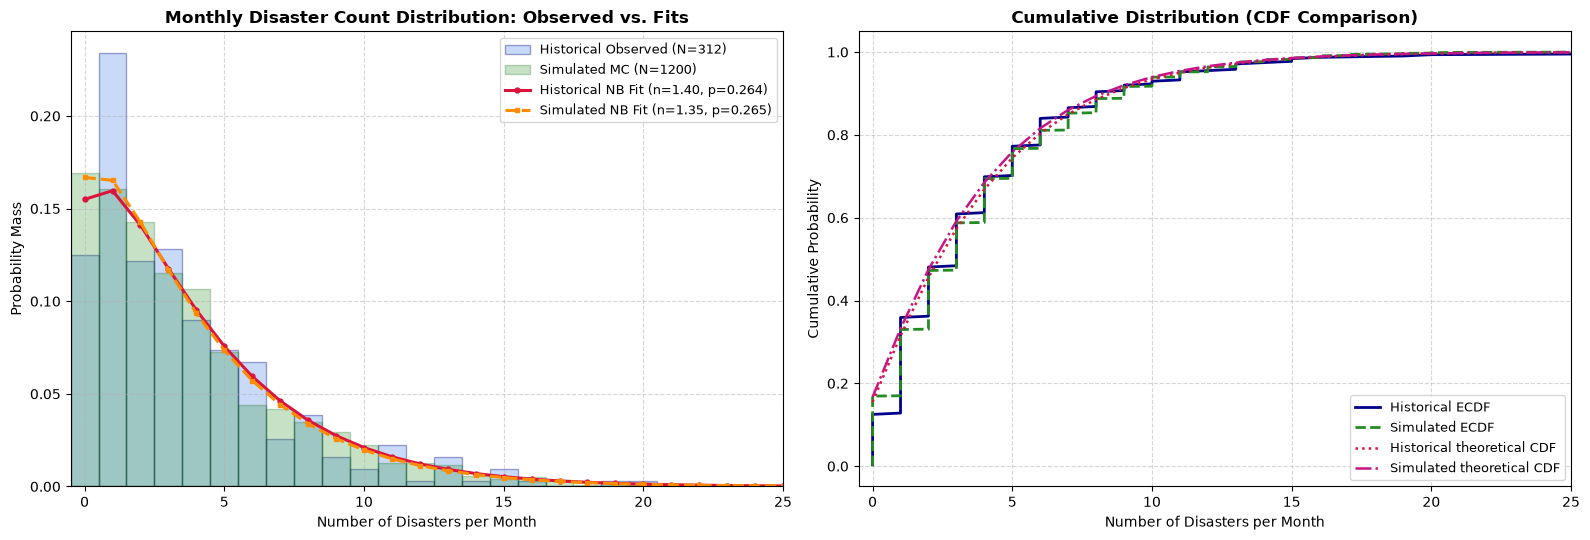

MONTHLY DISASTER COUNT DIAGNOSTICS:
  Historical target parameters : n = 1.4000, p = 0.2640
  Simulated recovered params   : n = 1.3470, p = 0.2646
  Delta n                      : 0.0530 (3.79%)
  Delta p                      : 0.0006 (0.23%)
-----------------------------------------------------------------
TWO-SAMPLE KS TEST (Simulated vs. Historical):
  KS Statistic: 0.0442
  p-value:      0.7001 (Good agreement)


In [24]:
_df_h = df_raw_events.copy()
_df_h["Start Date"] = pd.to_datetime(_df_h["Start Date"])
_m_range = pd.period_range("2000-01", "2025-12", freq="M")
y_hist = (
    _df_h[_df_h["Start Year"] >= 2000]
    .groupby(_df_h["Start Date"].dt.to_period("M"))["DisNo."]
    .count()
    .reindex(_m_range, fill_value=0)
    .to_numpy(dtype=int)
)
n_hist_samples = len(y_hist)
mean_hist, var_hist = np.mean(y_hist), np.var(y_hist, ddof=1)

n_hist, p_hist = 1.4, 0.264

_non_zero = df_event_scenarios.groupby(["scenario_id", "year", "month"]).size().to_numpy(dtype=int)
_total_months = N_SCENARIOS * N_YEARS * 12
y_sim = np.concatenate([_non_zero, np.zeros(max(0, _total_months - len(_non_zero)), dtype=int)])

n_sim_samples = len(y_sim)
mean_sim, var_sim = np.mean(y_sim), np.var(y_sim, ddof = 1)
p_init_sim = mean_sim / var_sim if var_sim > mean_sim else 0.5
n_init_sim = (mean_sim**2) / (var_sim - mean_sim) if var_sim > mean_sim else 1.0

res_sim = minimize(
    nll_nbinom, 
    x0=[n_init_sim, p_init_sim], 
    args=(y_sim,), 
    method="L-BFGS-B", 
    bounds=[(1e-4, 50.0), (1e-4, 0.999)]
)
n_sim, p_sim = res_sim.x

fit_table = pd.DataFrame([
    {
        "Dataset" : "Historical Observed",
        "Sample size" : n_hist_samples,
        "Mean" : round(mean_hist, 3),
        "Variance" : round(var_hist, 3),
        "Fitted n" : round(n_hist, 4),
        "Fitted p" : round(p_hist, 4),
    },
    {
        "Dataset" : "Simulated MC",
        "Sample size" : n_sim_samples,
        "Mean" : round(mean_sim, 3),
        "Variance" : round(var_sim, 3),
        "Fitted n" : round(n_sim, 4),
        "Fitted p" : round(p_sim, 4)
    }
])
display(fit_table)

fig, axes = plt.subplots(1, 2, figsize = (16, 5.5))
max_k = max(int(np.max(y_hist)), int(np.max(y_sim))) + 1
k_vals = np.arange(0, max_k + 1)
bins_k = np.arange(-0.5, max_k + 1.5, 1)

axes[0].hist(
    y_hist, 
    bins=bins_k, 
    density=True, 
    alpha=0.35, 
    color="cornflowerblue", 
    edgecolor="navy", 
    label=f"Historical Observed (N={n_hist_samples})"
)
axes[0].hist(
    y_sim, 
    bins=bins_k, 
    density=True, 
    alpha=0.25, 
    color="forestgreen", 
    edgecolor="darkgreen", 
    label=f"Simulated MC (N={n_sim_samples})"
)
axes[0].plot(
    k_vals, 
    stats.nbinom.pmf(k_vals, n_hist, p_hist), 
    color="crimson", 
    linewidth=2.2, 
    marker="o", 
    markersize=3.5, 
    label=f"Historical NB Fit (n={n_hist:.2f}, p={p_hist:.3f})"
)
axes[0].plot(
    k_vals, 
    stats.nbinom.pmf(k_vals, n_sim, p_sim), 
    color="darkorange", 
    linewidth=2.2, 
    linestyle="--", 
    marker="s", 
    markersize=3.5, 
    label=f"Simulated NB Fit (n={n_sim:.2f}, p={p_sim:.3f})"
)
axes[0].set_title("Monthly Disaster Count Distribution: Observed vs. Fits", weight="bold")
axes[0].set_xlabel("Number of Disasters per Month")
axes[0].set_ylabel("Probability Mass")
axes[0].set_xlim(-0.5, min(max_k + 0.5, 25))  # focus on relevant range
axes[0].legend(fontsize=9, loc="upper right")
axes[0].grid(True, linestyle="--", alpha=0.5)

sorted_hist = np.sort(y_hist)
ecdf_hist = np.arange(1, len(sorted_hist) + 1) / len(sorted_hist)
sorted_sim = np.sort(y_sim)
ecdf_sim = np.arange(1, len(sorted_sim) + 1) / len(sorted_sim)

axes[1].plot(sorted_hist, ecdf_hist, color = "darkblue", linewidth = 2.0, label = "Historical ECDF")
axes[1].plot(sorted_sim, ecdf_sim, color = "forestgreen", linewidth = 2.0, linestyle = "--", label = "Simulated ECDF")
axes[1].plot(k_vals, stats.nbinom.cdf(k_vals, n_hist, p_hist), color = "crimson", linewidth = 1.8, linestyle = ":", label = "Historical theoretical CDF")
axes[1].plot(k_vals, stats.nbinom.cdf(k_vals, n_sim, p_sim), color = "mediumvioletred", linewidth = 1.8, linestyle = "-.", label = "Simulated theoretical CDF")

axes[1].set_title("Cumulative Distribution (CDF Comparison)", weight="bold")
axes[1].set_xlabel("Number of Disasters per Month")
axes[1].set_ylabel("Cumulative Probability")
axes[1].set_xlim(-0.5, min(max_k + 0.5, 25))
axes[1].legend(fontsize=9, loc="lower right")
axes[1].grid(True, linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

ks_stat_month, ks_pval_month = stats.ks_2samp(y_sim, y_hist)
print("=" * 65)
print("MONTHLY DISASTER COUNT DIAGNOSTICS:")
print(f"  Historical target parameters : n = {n_hist:.4f}, p = {p_hist:.4f}")
print(f"  Simulated recovered params   : n = {n_sim:.4f}, p = {p_sim:.4f}")
print(f"  Delta n                      : {abs(n_sim - n_hist):.4f} ({abs(n_sim - n_hist)/n_hist*100:.2f}%)")
print(f"  Delta p                      : {abs(p_sim - p_hist):.4f} ({abs(p_sim - p_hist)/p_hist*100:.2f}%)")
print("-" * 65)
print(f"TWO-SAMPLE KS TEST (Simulated vs. Historical):")
print(f"  KS Statistic: {ks_stat_month:.4f}")
print(f"  p-value:      {ks_pval_month:.4f} ({'Good agreement' if ks_pval_month > 0.05 else 'Statistically distinct'})")
print("=" * 65)


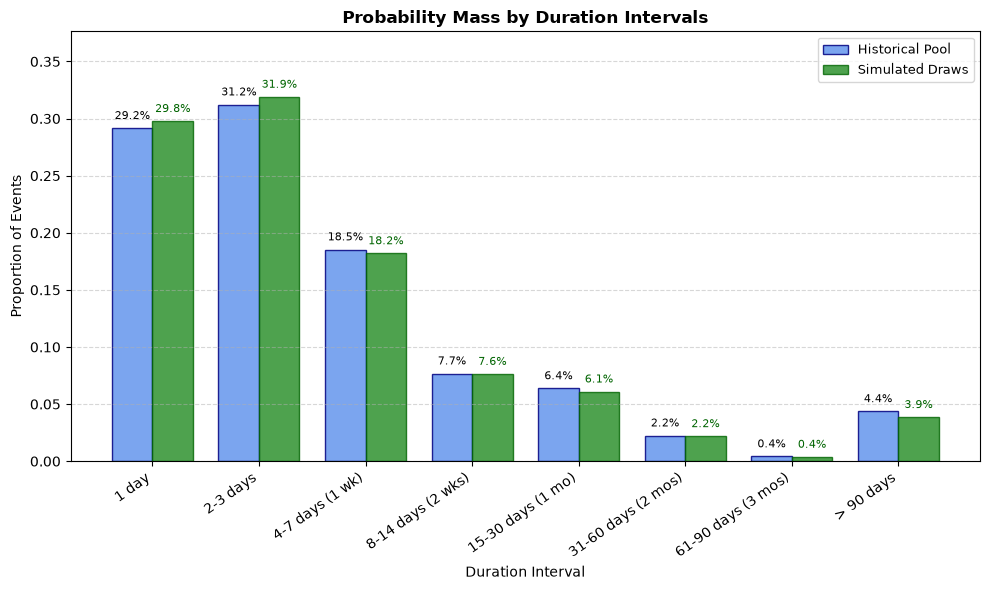

DURATION EMPIRICAL POOLING DIAGNOSTICS:
  Historical Events Sampled : N = 1,694 | Median = 3.0 d | Mean = 10.45 d
  Simulated Events Drawn    : N = 5,320 | Median = 2.0 d | Mean = 9.85 d
  Two-Sample KS Statistic   : D = 0.0137 (p-value: 0.9651)


In [23]:
raw_durs = df_raw_events["event_duration"].dropna()
raw_durs = raw_durs[raw_durs > 0].to_numpy(dtype=int)

sim_durs = df_event_scenarios["duration_days"].dropna()
sim_durs = sim_durs[sim_durs > 0].to_numpy(dtype=int)

fig, ax = plt.subplots(figsize=(10, 6))

bucket_bins = [0, 1, 3, 7, 14, 30, 60, 90, np.inf]
bucket_labels = [
    "1 day", 
    "2-3 days", 
    "4-7 days (1 wk)", 
    "8-14 days (2 wks)", 
    "15-30 days (1 mo)", 
    "31-60 days (2 mos)", 
    "61-90 days (3 mos)", 
    "> 90 days"
]

raw_binned = pd.Series(pd.cut(raw_durs, bins=bucket_bins, labels=bucket_labels))
sim_binned = pd.Series(pd.cut(sim_durs, bins=bucket_bins, labels=bucket_labels))

df_buckets = pd.DataFrame({
    "Historical": raw_binned.value_counts(normalize=True).reindex(bucket_labels, fill_value=0.0),
    "Simulated": sim_binned.value_counts(normalize=True).reindex(bucket_labels, fill_value=0.0)
})

x_pos = np.arange(len(bucket_labels))
bar_width = 0.38

ax.bar(
    x_pos - bar_width/2, 
    df_buckets["Historical"], 
    width=bar_width, 
    color="cornflowerblue", 
    edgecolor="navy", 
    alpha=0.85, 
    label="Historical Pool"
)
ax.bar(
    x_pos + bar_width/2, 
    df_buckets["Simulated"], 
    width=bar_width, 
    color="forestgreen", 
    edgecolor="darkgreen", 
    alpha=0.80, 
    label="Simulated Draws"
)

for i in x_pos:
    val_raw = df_buckets["Historical"].iloc[i]
    val_sim = df_buckets["Simulated"].iloc[i]
    ax.text(i - bar_width/2, val_raw + 0.008, f"{val_raw:.1%}", ha="center", fontsize=8)
    ax.text(i + bar_width/2, val_sim + 0.008, f"{val_sim:.1%}", ha="center", fontsize=8, color="darkgreen")

ax.set_title("Probability Mass by Duration Intervals", weight="bold")
ax.set_xlabel("Duration Interval")
ax.set_ylabel("Proportion of Events")
ax.set_xticks(x_pos)
ax.set_xticklabels(bucket_labels, rotation=35, ha="right")
ax.set_ylim(0, max(df_buckets.max()) * 1.18)
ax.legend(fontsize=9, loc="upper right")
ax.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

ks_stat_dur, ks_pval_dur = stats.ks_2samp(sim_durs, raw_durs)
print("=" * 65)
print("DURATION EMPIRICAL POOLING DIAGNOSTICS:")
print(f"  Historical Events Sampled : N = {len(raw_durs):,} | Median = {np.median(raw_durs):.1f} d | Mean = {np.mean(raw_durs):.2f} d")
print(f"  Simulated Events Drawn    : N = {len(sim_durs):,} | Median = {np.median(sim_durs):.1f} d | Mean = {np.mean(sim_durs):.2f} d")
print(f"  Two-Sample KS Statistic   : D = {ks_stat_dur:.4f} (p-value: {ks_pval_dur:.4f})")
print("=" * 65)

In [25]:
# Aggregate total closure days per scenario across candidate warehouses
scenario_impacts = (
    df_facility_hits.groupby(["scenario_id", "warehouse"])["days_closed"]
    .sum()
    .unstack(fill_value=0)
)
scenario_impacts["Total_Network_Downtime"] = scenario_impacts.sum(axis=1)

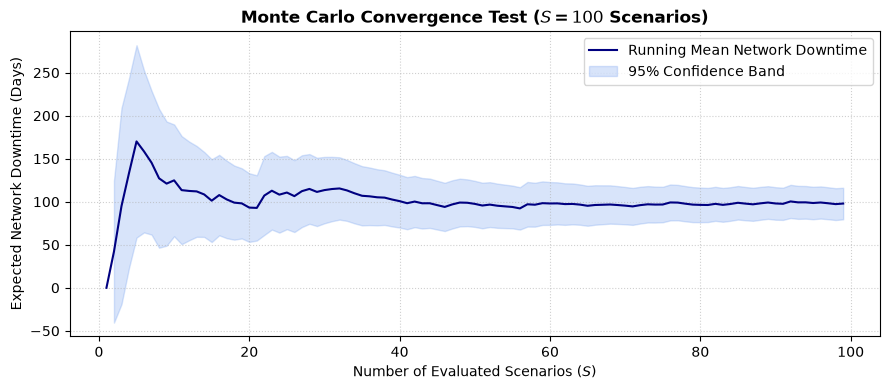

In [26]:
running_means = scenario_impacts["Total_Network_Downtime"].expanding().mean()
running_std = scenario_impacts["Total_Network_Downtime"].expanding().std()

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(range(1, len(running_means) + 1), running_means, color="navy", label="Running Mean Network Downtime")
ax.fill_between(
    range(1, len(running_means) + 1),
    running_means - 1.96 * (running_std / np.sqrt(range(1, len(running_means) + 1))),
    running_means + 1.96 * (running_std / np.sqrt(range(1, len(running_means) + 1))),
    color="cornflowerblue", alpha=0.25, label="95% Confidence Band"
)
ax.set_title("Monte Carlo Convergence Test ($S = 100$ Scenarios)", weight="bold")
ax.set_xlabel("Number of Evaluated Scenarios ($S$)")
ax.set_ylabel("Expected Network Downtime (Days)")
ax.legend()
ax.grid(True, linestyle=":", alpha=0.6)
plt.tight_layout()
plt.show()

# Else

In [ ]:
# Copute historical damage threshold to categorize disaster severity

raw_damage = df_raw_events["Total Damage, Adjusted ('000 US$)"].dropna()
raw_damage = raw_damage[raw_damage > 0].to_numpy()

percentile_levels = np.linspace(0, 100, 11)
damage_anchors = np.quantile(raw_damage, percentile_levels / 100.0)

print(f"HISTORICAL_DAMAGE_ANCHORS = {[round(float(x), 2) for x in damage_anchors]}")
print(f"PERCENTILE_ANCHORS = {[round(float(p), 1) for p in percentile_levels]}")

HISTORICAL_DAMAGE_ANCHORS = [21.0, 8579.0, 22435.0, 58492.8, 127440.2, 201517.0, 319702.2, 615005.8, 1147839.0, 2446295.8, 78133584.0]
PERCENTILE_ANCHORS = [0.0, 10.0, 20.0, 30.0, 40.0, 50.0, 60.0, 70.0, 80.0, 90.0, 100.0]
